# [Student] 🐼 Pandas for Data Analysis: Basics + Customer Churn Project
**Section 1:** learn pandas functions and attributes on small examples (no file needed).  
**Section 2:** a real project on `customer_churn.csv`: clean → explore → visualise → model.

---
## Section 2 preview: the story
### 🎬 The story
You've just joined **KeralaNet Broadband** as a junior data analyst. On day one your manager drops a file on your desk:

> *"We're losing customers every month and nobody knows why. Here's our customer data, `customer_churn.csv`. Find out **who** is leaving, **why** they leave, and build something that can **warn us early**."*

Section 2 of this notebook is your project. Work through Parts A–F. Each ✏️ **Question** has an empty code cell for your answer. 💡 **Business insight** cells ask you to explain what the numbers mean, in plain words, as you would to your manager.

| Part | What you'll do |
|---|---|
| A | Meet the data |
| B | Clean the data |
| C | EDA: answer the manager's questions |
| C2 | Visualising with Matplotlib |
| D | Prepare the data for a model |
| E | Build a logistic regression model |
| F | Recommendations and challenges |

You only need `customer_churn.csv` from **Section 2** onwards. Section 1 needs no files.

## Setup (run this cell)

In [82]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (8, 4)


---
# 📘 SECTION 1: Pandas Basics
Before the project, let's learn the main **functions, attributes and methods** of pandas on small tables we type in ourselves. **No CSV is needed for this section.**

> **Attribute** is a fact about an object; there are no brackets: `df.shape`, `s.size`
> **Method** is an action; it needs brackets: `df.head()`, `s.mean()`
> **Function** is called from `pd`: `pd.Series()`, `pd.DataFrame()`, `pd.read_csv()`

## 1.1 Series: a single column of data

In [83]:
prices = pd.Series([120, 40, 90, 50], index=["Mango", "Banana", "Jackfruit", "Papaya"])
prices

Mango        120
Banana        40
Jackfruit     90
Papaya        50
dtype: int64

In [84]:
# Attributes (no brackets)
print("size     :", prices.size)
print("dtype    :", prices.dtype)
print("index    :", list(prices.index))
print("values   :", prices.values)
print("is_unique:", prices.is_unique)

size     : 4
dtype    : int64
index    : ['Mango', 'Banana', 'Jackfruit', 'Papaya']
values   : [120  40  90  50]
is_unique: True


In [85]:
# Methods (with brackets)
print("sum :", prices.sum())
print("mean:", prices.mean())
print("max :", prices.max(), "| idxmax:", prices.idxmax())
prices.sort_values(ascending=False)

sum : 300
mean: 75.0
max : 120 | idxmax: Mango


Mango        120
Jackfruit     90
Papaya        50
Banana        40
dtype: int64

### ✏️ Question 1.1a
Create a Series `marks` from a **dictionary**: `{'Anu': 78, 'Ben': 92, 'Chitra': 65, 'Dev': 88, 'Esha': 92}`. Print its `size`, `mean()`, `median()`, `mode()` and `is_unique`.

In [86]:
marks = pd.Series({"Anu": 78, "Ben": 92, "Chitra": 65, "Dev": 88, "Esha": 92})

print("size     :", marks.size)
print("mean     :", marks.mean())
print("median   :", marks.median())
print("mode     :", marks.mode().tolist())   # mode() returns a Series (there can be ties)
print("is_unique:", marks.is_unique)

size     : 5
mean     : 83.0
median   : 88.0
mode     : [92]
is_unique: False


### ✏️ Question 1.1b
Who scored the highest and the lowest in `marks`? Sort the marks from highest to lowest.

In [87]:
print("Highest:", marks.idxmax(), "->", marks.max())   
print("Lowest :", marks.idxmin(), "->", marks.min())
marks.sort_values(ascending=False)

Highest: Ben -> 92
Lowest : Chitra -> 65


Ben       92
Esha      92
Dev       88
Anu       78
Chitra    65
dtype: int64

## 1.2 Selecting values: `iloc`, `loc`, `get`
- `iloc[...]` selects by **position** (0, 1, 2…)
- `loc[...]` selects by **label**
- `get(label, default)` selects by label without raising an error if the label is missing

In [88]:
print(prices.iloc[0])            
print(prices.loc["Banana"])       
print(prices.iloc[1:3])           
print(prices.get("Apple", "Not found"))

120
40
Banana       40
Jackfruit    90
dtype: int64
Not found


### ✏️ Question 1.2a
From `marks`, get (a) the 3rd value by position, (b) Dev's mark by label, (c) the last two values, (d) `'Farah'` with a default of `0`.

In [89]:
print("(a) 3rd value by position :", marks.iloc[2])
print("(b) Dev's mark by label    :", marks.loc["Dev"])
print("(c) last two values        :")
print(marks.iloc[-2:])
print("(d) Farah with default 0   :", marks.get("Farah", 0))

(a) 3rd value by position : 65
(b) Dev's mark by label    : 88
(c) last two values        :
Dev     88
Esha    92
dtype: int64
(d) Farah with default 0   : 0


## 1.3 Broadcasting, `value_counts`, `apply`, `map`

In [90]:
print(prices * 1.18)          

colours = pd.Series(["Red", "Blue", "Red", "Green", "Red", "Blue"])
print(colours.value_counts())
print(colours.value_counts(normalize=True))  

Mango        141.6
Banana        47.2
Jackfruit    106.2
Papaya        59.0
dtype: float64
Red      3
Blue     2
Green    1
Name: count, dtype: int64
Red      0.500000
Blue     0.333333
Green    0.166667
Name: proportion, dtype: float64


In [91]:
def grade(m):
    return "A" if m >= 90 else "B" if m >= 75 else "C"

print(marks.apply(grade))                                # apply runs a function on every value
print(colours.map({"Red": "R", "Blue": "B", "Green": "G"}))   # map swaps values using a dict

Anu       B
Ben       A
Chitra    C
Dev       B
Esha      A
dtype: object
0    R
1    B
2    R
3    G
4    R
5    B
dtype: object


### ✏️ Question 1.3a
Give every student in `marks` 5 grace marks, then use `apply(grade)` to find each student's grade. How many students got each grade?

In [92]:
with_grace = marks + 5                 
grades = with_grace.apply(grade)       

print(pd.DataFrame({"Marks+5": with_grace, "Grade": grades}))
print()
print(grades.value_counts())

        Marks+5 Grade
Anu          83     B
Ben          97     A
Chitra       70     C
Dev          93     A
Esha         97     A

A    3
B    1
C    1
Name: count, dtype: int64


## 1.4 DataFrames: a table of Series

In [93]:
emp = pd.DataFrame({
    "Name":   ["Asha", "Ravi", "Meera", "John", "Fathima", "Kiran", "Ravi"],
    "Dept":   ["IT", "HR", "IT", "Sales", "HR", "Sales", "HR"],
    "Age":    [28, 35, None, 42, 30, 25, 35],
    "Salary": [55000, 48000, 62000, 70000, None, 39000, 48000],
    "City":   [" kochi", "Thrissur", "KOCHI ", "Kollam", "thrissur", "Kochi", "Thrissur"],
    "Joined": ["2021-03-15", "2018-07-01", "2020-01-10", "2015-11-20", "2022-05-05", "2023-02-01", "2018-07-01"],
})
emp

,Name,Dept,Age,Salary,City,Joined
0,Asha,IT,28.0,55000.0,kochi,2021-03-15
1,Ravi,HR,35.0,48000.0,Thrissur,2018-07-01
2,Meera,IT,NaN,62000.0,KOCHI,2020-01-10
3,John,Sales,42.0,70000.0,Kollam,2015-11-20
4,Fathima,HR,30.0,NaN,thrissur,2022-05-05
5,Kiran,Sales,25.0,39000.0,Kochi,2023-02-01
6,Ravi,HR,35.0,48000.0,Thrissur,2018-07-01


In [94]:
# Attributes
print("shape  :", emp.shape)
print("columns:", list(emp.columns))
print("index  :", emp.index)
print(emp.dtypes)

shape  : (7, 6)
columns: ['Name', 'Dept', 'Age', 'Salary', 'City', 'Joined']
index  : RangeIndex(start=0, stop=7, step=1)
Name       object
Dept       object
Age       float64
Salary    float64
City       object
Joined     object
dtype: object


In [95]:
emp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Name    7 non-null      object 
 1   Dept    7 non-null      object 
 2   Age     6 non-null      float64
 3   Salary  6 non-null      float64
 4   City    7 non-null      object 
 5   Joined  7 non-null      object 
dtypes: float64(2), object(4)
memory usage: 464.0+ bytes


In [96]:
emp.describe()

,Age,Salary
count,6.000000,6.000000
mean,32.500000,53666.666667
std,6.090977,11111.555547
min,25.000000,39000.000000
25%,28.500000,48000.000000
50%,32.500000,51500.000000
75%,35.000000,60250.000000
max,42.000000,70000.000000


### ✏️ Question 1.4a
Show the first 3 rows and the last 2 rows of `emp`. How many rows and columns does it have?

In [97]:
print(emp.head(3))
print()
print(emp.tail(2))
print()
print("Rows:", emp.shape[0], "| Columns:", emp.shape[1])

    Name Dept   Age   Salary      City      Joined
0   Asha   IT  28.0  55000.0     kochi  2021-03-15
1   Ravi   HR  35.0  48000.0  Thrissur  2018-07-01
2  Meera   IT   NaN  62000.0    KOCHI   2020-01-10

    Name   Dept   Age   Salary      City      Joined
5  Kiran  Sales  25.0  39000.0     Kochi  2023-02-01
6   Ravi     HR  35.0  48000.0  Thrissur  2018-07-01

Rows: 7 | Columns: 6


## 1.5 Working with columns

In [98]:
print(type(emp["Name"]))          
emp[["Name", "Salary"]]          

<class 'pandas.core.series.Series'>


,Name,Salary
0,Asha,55000.0
1,Ravi,48000.0
2,Meera,62000.0
3,John,70000.0
4,Fathima,NaN
5,Kiran,39000.0
6,Ravi,48000.0


In [99]:
emp["Bonus"] = emp["Salary"] * 0.10                    
emp = emp.rename(columns={"Dept": "Department"})        
emp.head(3)

,Name,Department,Age,Salary,City,Joined,Bonus
0,Asha,IT,28.0,55000.0,kochi,2021-03-15,5500.0
1,Ravi,HR,35.0,48000.0,Thrissur,2018-07-01,4800.0
2,Meera,IT,NaN,62000.0,KOCHI,2020-01-10,6200.0


In [100]:
emp = emp.drop(columns="Bonus")                        
emp["Department"] = emp["Department"].astype("category") 
emp.dtypes

Name            object
Department    category
Age            float64
Salary         float64
City            object
Joined          object
dtype: object

### ✏️ Question 1.5a
Add a column `Salary_Lakhs` = `Salary / 100000`, rounded to 2 decimals. Show only `Name` and `Salary_Lakhs`.

In [101]:
emp_l = emp.copy()    
emp_l["Salary_Lakhs"] = (emp_l["Salary"] / 100000).round(2)
emp_l[["Name", "Salary_Lakhs"]]

,Name,Salary_Lakhs
0,Asha,0.55
1,Ravi,0.48
2,Meera,0.62
3,John,0.70
4,Fathima,NaN
5,Kiran,0.39
6,Ravi,0.48


## 1.6 Filtering rows
A filter is a **True/False Series** placed inside `df[...]`. Combine filters with `&` (AND), `|` (OR) and `~` (NOT), and always put brackets around each condition.

In [102]:
emp[emp["Age"] > 30]

,Name,Department,Age,Salary,City,Joined
1,Ravi,HR,35.0,48000.0,Thrissur,2018-07-01
3,John,Sales,42.0,70000.0,Kollam,2015-11-20
6,Ravi,HR,35.0,48000.0,Thrissur,2018-07-01


In [103]:
emp[(emp["Department"] == "HR") & (emp["Salary"] > 45000)]

,Name,Department,Age,Salary,City,Joined
1,Ravi,HR,35.0,48000.0,Thrissur,2018-07-01
6,Ravi,HR,35.0,48000.0,Thrissur,2018-07-01


In [104]:
print(emp[emp["Department"].isin(["IT", "Sales"])]["Name"].tolist())
print(emp[emp["Age"].between(25, 32)]["Name"].tolist())
emp[emp["Salary"].isnull()]

['Asha', 'Meera', 'John', 'Kiran']
['Asha', 'Fathima', 'Kiran']


,Name,Department,Age,Salary,City,Joined
4,Fathima,HR,30.0,NaN,thrissur,2022-05-05


### ✏️ Question 1.6a
Find the employees who work in **IT or Sales** and earn **more than 50,000**.

In [105]:
emp[emp["Department"].isin(["IT", "Sales"]) & (emp["Salary"] > 50000)]

,Name,Department,Age,Salary,City,Joined
0,Asha,IT,28.0,55000.0,kochi,2021-03-15
2,Meera,IT,NaN,62000.0,KOCHI,2020-01-10
3,John,Sales,42.0,70000.0,Kollam,2015-11-20


## 1.7 Missing values and duplicates

In [106]:
print(emp.isnull().sum())
print("Duplicate rows:", emp.duplicated().sum())

Name          0
Department    0
Age           1
Salary        1
City          0
Joined        0
dtype: int64
Duplicate rows: 1


In [107]:
clean = emp.drop_duplicates().copy()
clean["Age"] = clean["Age"].fillna(clean["Age"].median())
clean["Salary"] = clean["Salary"].fillna(clean["Salary"].mean())
print(clean.isnull().sum().sum(), "missing values left")
clean

0 missing values left


,Name,Department,Age,Salary,City,Joined
0,Asha,IT,28.0,55000.0,kochi,2021-03-15
1,Ravi,HR,35.0,48000.0,Thrissur,2018-07-01
2,Meera,IT,30.0,62000.0,KOCHI,2020-01-10
3,John,Sales,42.0,70000.0,Kollam,2015-11-20
4,Fathima,HR,30.0,54800.0,thrissur,2022-05-05
5,Kiran,Sales,25.0,39000.0,Kochi,2023-02-01


### ✏️ Question 1.7a
Starting from `emp` again, use `dropna()` to drop every row that has **any** missing value. How many rows are left? Why might this be a bad idea in real data?

In [108]:
dropped = emp.dropna()
print("Rows left:", len(dropped), "(from", len(emp), ")")
dropped

Rows left: 5 (from 7 )


,Name,Department,Age,Salary,City,Joined
0,Asha,IT,28.0,55000.0,kochi,2021-03-15
1,Ravi,HR,35.0,48000.0,Thrissur,2018-07-01
3,John,Sales,42.0,70000.0,Kollam,2015-11-20
5,Kiran,Sales,25.0,39000.0,Kochi,2023-02-01
6,Ravi,HR,35.0,48000.0,Thrissur,2018-07-01


## 1.8 Text (`.str`) and dates (`.dt`)

In [109]:
clean["City"]

0       kochi
1    Thrissur
2      KOCHI 
3      Kollam
4    thrissur
5       Kochi
Name: City, dtype: object

In [110]:
for city in clean["City"]:
    print(repr(city), "-> length:", len(city))

' kochi' -> length: 6
'Thrissur' -> length: 8
'KOCHI ' -> length: 6
'Kollam' -> length: 6
'thrissur' -> length: 8
'Kochi' -> length: 5


In [111]:
clean["City"].str.len()

0    6
1    8
2    6
3    6
4    8
5    5
Name: City, dtype: int64

In [112]:
stripped = clean["City"].str.strip()
print(stripped.tolist())
print(stripped.str.len().tolist())

['kochi', 'Thrissur', 'KOCHI', 'Kollam', 'thrissur', 'Kochi']
[5, 8, 5, 6, 8, 5]


In [113]:
print(clean["City"].str.lstrip().tolist())
print(clean["City"].str.rstrip().tolist())

['kochi', 'Thrissur', 'KOCHI ', 'Kollam', 'thrissur', 'Kochi']
[' kochi', 'Thrissur', 'KOCHI', 'Kollam', 'thrissur', 'Kochi']


In [114]:
print(stripped.str.lower().tolist())   
print(stripped.str.upper().tolist())   
print(stripped.str.title().tolist())  

['kochi', 'thrissur', 'kochi', 'kollam', 'thrissur', 'kochi']
['KOCHI', 'THRISSUR', 'KOCHI', 'KOLLAM', 'THRISSUR', 'KOCHI']
['Kochi', 'Thrissur', 'Kochi', 'Kollam', 'Thrissur', 'Kochi']


In [115]:
clean["City"].str.strip()

0       kochi
1    Thrissur
2       KOCHI
3      Kollam
4    thrissur
5       Kochi
Name: City, dtype: object

In [116]:
clean["City"].str.strip().str.title()

0       Kochi
1    Thrissur
2       Kochi
3      Kollam
4    Thrissur
5       Kochi
Name: City, dtype: object

In [117]:
clean["City"].value_counts()

City
 kochi      1
Thrissur    1
KOCHI       1
Kollam      1
thrissur    1
Kochi       1
Name: count, dtype: int64

In [118]:
clean["City"] = clean["City"].str.strip().str.title()
print(clean["City"].value_counts())

City
Kochi       3
Thrissur    2
Kollam      1
Name: count, dtype: int64


In [119]:
print(clean[clean["Name"].str.contains("a")]["Name"].tolist())   # names containing 'a'
print(clean["Name"].str.upper().tolist())

['Asha', 'Ravi', 'Meera', 'Fathima', 'Kiran']
['ASHA', 'RAVI', 'MEERA', 'JOHN', 'FATHIMA', 'KIRAN']


In [120]:
clean["City"] = clean["City"].str.strip().str.title()
print(clean["City"].value_counts())
print(clean[clean["Name"].str.contains("a")]["Name"].tolist())   # names containing 'a'
print(clean["Name"].str.upper().tolist())

City
Kochi       3
Thrissur    2
Kollam      1
Name: count, dtype: int64
['Asha', 'Ravi', 'Meera', 'Fathima', 'Kiran']
['ASHA', 'RAVI', 'MEERA', 'JOHN', 'FATHIMA', 'KIRAN']


In [121]:
clean["Joined"]

0    2021-03-15
1    2018-07-01
2    2020-01-10
3    2015-11-20
4    2022-05-05
5    2023-02-01
Name: Joined, dtype: object

In [122]:
clean["Joined"] = pd.to_datetime(clean["Joined"])
clean["Joined"]

0   2021-03-15
1   2018-07-01
2   2020-01-10
3   2015-11-20
4   2022-05-05
5   2023-02-01
Name: Joined, dtype: datetime64[ns]

In [123]:
clean["JoinYear"] = clean["Joined"].dt.year
clean["JoinYear"]

0    2021
1    2018
2    2020
3    2015
4    2022
5    2023
Name: JoinYear, dtype: int32

In [124]:
clean["JoinDay"] = clean["Joined"].dt.day_name()
clean[["Name", "Joined", "JoinYear", "JoinDay"]]

,Name,Joined,JoinYear,JoinDay
0,Asha,2021-03-15,2021,Monday
1,Ravi,2018-07-01,2018,Sunday
2,Meera,2020-01-10,2020,Friday
3,John,2015-11-20,2015,Friday
4,Fathima,2022-05-05,2022,Thursday
5,Kiran,2023-02-01,2023,Wednesday


In [125]:
clean["Joined"] = pd.to_datetime(clean["Joined"])
clean["JoinYear"] = clean["Joined"].dt.year
clean["JoinDay"] = clean["Joined"].dt.day_name()
clean[["Name", "Joined", "JoinYear", "JoinDay"]]

,Name,Joined,JoinYear,JoinDay
0,Asha,2021-03-15,2021,Monday
1,Ravi,2018-07-01,2018,Sunday
2,Meera,2020-01-10,2020,Friday
3,John,2015-11-20,2015,Friday
4,Fathima,2022-05-05,2022,Thursday
5,Kiran,2023-02-01,2023,Wednesday


### ✏️ Question 1.8a
Which employees joined **before 2020**? Show their names and joining years.

In [126]:
clean[clean["Joined"].dt.year < 2020][["Name", "JoinYear"]]

,Name,JoinYear
1,Ravi,2018
3,John,2015


## 1.9 Grouping and sorting

**Why `observed=True`?** It only matters when the group-by column has the `category` dtype (we converted `Department` earlier).
- `observed=True` shows only the categories that actually **appear** in the data.
- `observed=False` shows **every** category, including empty ones, with NaN.
- Writing it explicitly avoids a FutureWarning in pandas 2.x and gives the same result in pandas 3.x.

In [127]:
clean.groupby("Department",observed=True)["Salary"].mean().round(0)

Department
HR       51400.0
IT       58500.0
Sales    54500.0
Name: Salary, dtype: float64

In [128]:
clean.groupby("Department", observed=True).agg(
    people=("Name", "count"),
    avg_salary=("Salary", "mean"),
    oldest=("Age", "max"),
).round(0)

,people,avg_salary,oldest
Department,,,
HR,2,51400.0,35.0
IT,2,58500.0,30.0
Sales,2,54500.0,42.0


In [129]:
print(clean.sort_values("Salary", ascending=False)[["Name", "Salary"]])
clean.nlargest(2, "Salary")[["Name", "Salary"]]

      Name   Salary
3     John  70000.0
2    Meera  62000.0
0     Asha  55000.0
4  Fathima  54800.0
1     Ravi  48000.0
5    Kiran  39000.0


,Name,Salary
3,John,70000.0
2,Meera,62000.0


### ✏️ Question 1.9a
Find the **average age per city**, sorted from highest to lowest.

In [130]:
clean.groupby("City")["Age"].mean().sort_values(ascending=False).round(1)

City
Kollam      42.0
Thrissur    32.5
Kochi       27.7
Name: Age, dtype: float64

## 1.10 Loops over columns
`df.dtypes` holds every column's data type (the same information `info()` prints), so we can loop over it.

In [131]:
for col, dtype in clean.dtypes.items():
    print(f"--- {col} ({dtype}) ---")
    if dtype == "int64" or dtype == "float64":
        print(clean[col].describe().round(1))
    else:
        print(clean[col].value_counts().head(3))

--- Name (object) ---
Name
Asha     1
Ravi     1
Meera    1
Name: count, dtype: int64
--- Department (category) ---
Department
HR       2
IT       2
Sales    2
Name: count, dtype: int64
--- Age (float64) ---
count     6.0
mean     31.7
std       6.0
min      25.0
25%      28.5
50%      30.0
75%      33.8
max      42.0
Name: Age, dtype: float64
--- Salary (float64) ---
count        6.0
mean     54800.0
std      10759.2
min      39000.0
25%      49700.0
50%      54900.0
75%      60250.0
max      70000.0
Name: Salary, dtype: float64
--- City (object) ---
City
Kochi       3
Thrissur    2
Kollam      1
Name: count, dtype: int64
--- Joined (datetime64[ns]) ---
Joined
2021-03-15    1
2018-07-01    1
2020-01-10    1
Name: count, dtype: int64
--- JoinYear (int32) ---
JoinYear
2021    1
2018    1
2020    1
Name: count, dtype: int64
--- JoinDay (object) ---
JoinDay
Friday    2
Monday    1
Sunday    1
Name: count, dtype: int64


### ✏️ Question 1.10a
Use `select_dtypes` to list the **numeric** columns and the **non-numeric** columns of `clean`.

In [132]:
numeric_list = clean.select_dtypes(include="number").columns.tolist()
non_numeric_list = clean.select_dtypes(exclude="number").columns.tolist()
print("Numeric    :", numeric_list)
print("Non-numeric:", non_numeric_list)

Numeric    : ['Age', 'Salary', 'JoinYear']
Non-numeric: ['Name', 'Department', 'City', 'Joined', 'JoinDay']


In [133]:
numeric_cols = clean.select_dtypes(include="number").columns
other_cols   = clean.select_dtypes(exclude="number").columns

for col in numeric_cols:
    print(f"--- {col} ---")
    print(clean[col].describe().round(1))

for col in other_cols:
    print(f"--- {col} ---")
    print(clean[col].value_counts().head(3))

--- Age ---
count     6.0
mean     31.7
std       6.0
min      25.0
25%      28.5
50%      30.0
75%      33.8
max      42.0
Name: Age, dtype: float64
--- Salary ---
count        6.0
mean     54800.0
std      10759.2
min      39000.0
25%      49700.0
50%      54900.0
75%      60250.0
max      70000.0
Name: Salary, dtype: float64
--- JoinYear ---
count       6.0
mean     2019.8
std         2.9
min      2015.0
25%      2018.5
50%      2020.5
75%      2021.8
max      2023.0
Name: JoinYear, dtype: float64
--- Name ---
Name
Asha     1
Ravi     1
Meera    1
Name: count, dtype: int64
--- Department ---
Department
HR       2
IT       2
Sales    2
Name: count, dtype: int64
--- City ---
City
Kochi       3
Thrissur    2
Kollam      1
Name: count, dtype: int64
--- Joined ---
Joined
2021-03-15    1
2018-07-01    1
2020-01-10    1
Name: count, dtype: int64
--- JoinDay ---
JoinDay
Friday    2
Monday    1
Sunday    1
Name: count, dtype: int64


## 1.11 Matplotlib basics

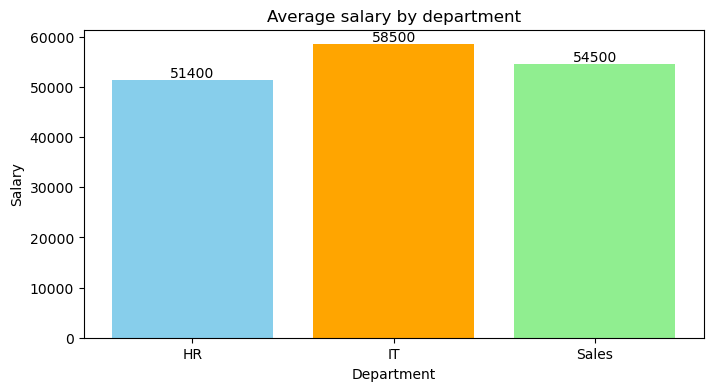

In [134]:
avg = clean.groupby("Department", observed=True)["Salary"].mean()

bars = plt.bar(avg.index, avg.values, color=["skyblue", "orange", "lightgreen"])
plt.bar_label(bars, fmt="%.0f")      # writes each bar's value on top

plt.title("Average salary by department")
plt.xlabel("Department")
plt.ylabel("Salary")
plt.show()

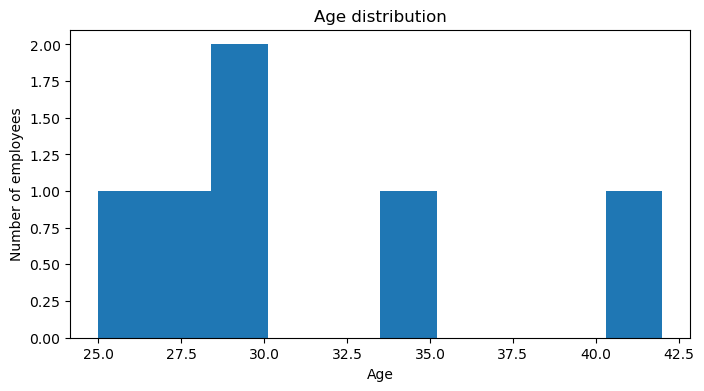

In [135]:
plt.hist(clean["Age"])
plt.title("Age distribution")
plt.xlabel("Age")
plt.ylabel("Number of employees")
plt.show()

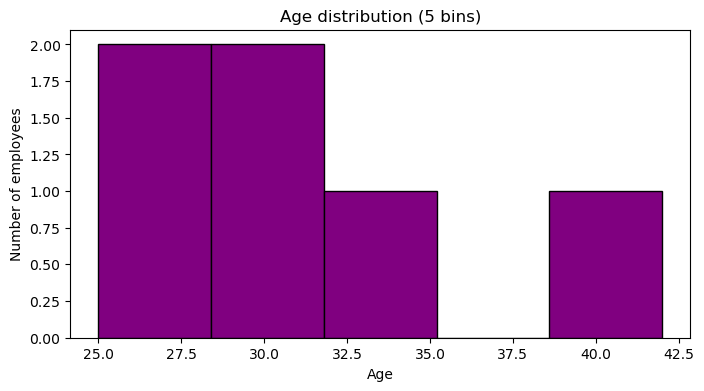

In [136]:
plt.hist(clean["Age"], bins=5, color="purple", edgecolor="black")
plt.title("Age distribution (5 bins)")
plt.xlabel("Age")
plt.ylabel("Number of employees")
plt.show()

**Why do the two histograms look different?** The first used matplotlib's default of **10 bins** (each 1.7 years wide); the second used **5 bins** (each 3.4 years wide). With wider bins, ages 25 and 28 fall into the same group.
The number of bins changes the **shape** of a histogram: too many and it looks spiky, too few and it hides detail. Run the cell below to see the exact bin edges and counts.

Bin edges: [25.  28.4 31.8 35.2 38.6 42. ]
Counts   : [2. 2. 1. 0. 1.]


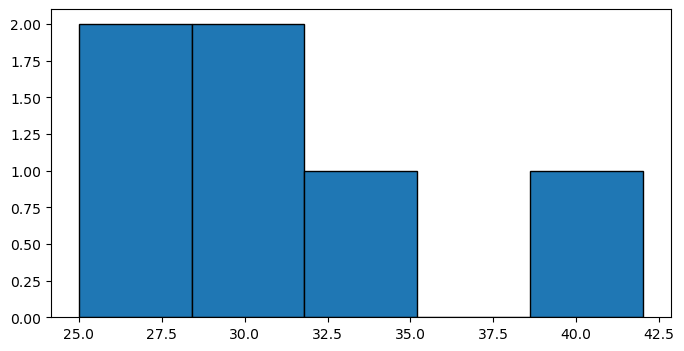

In [137]:
counts, edges, _ = plt.hist(clean["Age"], bins=5, edgecolor="black")
print("Bin edges:", edges.round(1))
print("Counts   :", counts)
plt.show()

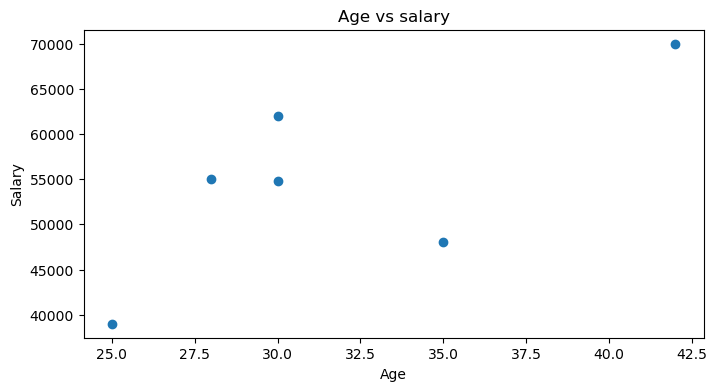

In [138]:
plt.scatter(clean["Age"], clean["Salary"])
plt.title("Age vs salary")
plt.xlabel("Age")
plt.ylabel("Salary")
plt.show()

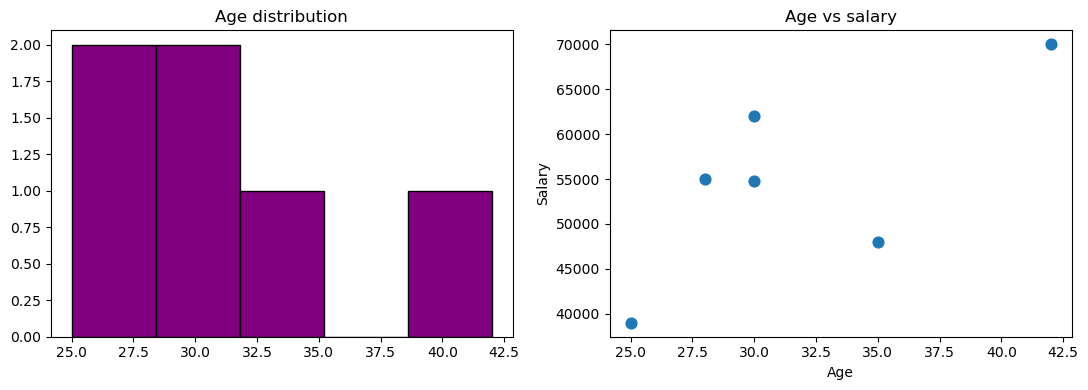

In [139]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.hist(clean["Age"], bins=5, color="purple", edgecolor="black")
ax1.set_title("Age distribution")

ax2.scatter(clean["Age"], clean["Salary"], s=60)
ax2.set_title("Age vs salary")
ax2.set_xlabel("Age")
ax2.set_ylabel("Salary")

plt.tight_layout() 
plt.show()

### ✏️ Question 1.11a
Draw a **horizontal bar chart** (`plt.barh`) of each employee's salary in `clean`, sorted from lowest to highest, with a title.

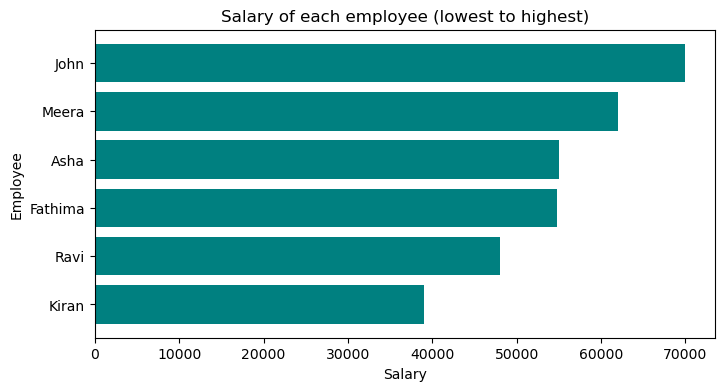

In [140]:
by_salary = clean.sort_values("Salary")          
plt.barh(by_salary["Name"], by_salary["Salary"], color="teal")
plt.title("Salary of each employee (lowest to highest)")
plt.xlabel("Salary")
plt.ylabel("Employee")
plt.show()

## 🧾 Recap: Attributes vs Methods vs Functions
| Attributes (no `()`) | Methods (`()`) | Functions (`pd.`) |
|---|---|---|
| `shape`, `size`, `columns`, `index`, `dtypes`, `values`, `is_unique` | `head`, `tail`, `info`, `describe`, `sum`, `mean`, `sort_values`, `value_counts`, `isnull`, `fillna`, `dropna`, `drop_duplicates`, `groupby`, `apply`, `map`, `rename`, `drop`, `astype` | `pd.Series`, `pd.DataFrame`, `pd.read_csv`, `pd.to_datetime`, `pd.concat`, `pd.get_dummies` |
| `.str` and `.dt` (accessors) | `.str.strip()`, `.str.title()`, `.dt.year`… | |

✅ **You're ready for the real project.**

---
# 📗 SECTION 2: The Churn Project
### ⬇️ Before you start
Download **`customer_churn.csv`** (shared by your instructor) and put it in the **same folder** as this notebook. Then continue below.

---
## Part A: Meet the Data 👋

### ✏️ Question A1
Load `customer_churn.csv` into a DataFrame called `df` and show the first 5 rows.

In [141]:
df = pd.read_csv("customer_churn.csv")
df.head()

,CustomerID,Name,Gender,Age,City,SignupDate,Plan,Contract,MonthlyCharges,TenureMonths,TotalCharges,SupportCalls,PaymentMethod,SeniorCitizen,SatisfactionScore,Churn
0,CUST1113,"Menon, Hari",Male,66.0,Bengaluru,09/07/2025,Standard,One year,521.61,13,6780.93,0,Debit Card,True,2.0,1
1,CUST1795,"Menon, Suresh",Male,18.0,KOLLAM,08/21/2026,Standard,One year,503.05,2,1006.10,2,Net Banking,False,1.0,1
2,CUST1817,"Menon, Arjun",NaN,74.0,Bengaluru,03/11/2023,Standard,One year,538.37,44,23688.28,3,UPI,True,4.0,0
3,CUST1510,"iyer, pooja",Female,66.0,Thiruvananthapuram,10/11/2025,Standard,Month-to-month,494.45,12,5933.40,2,Credit Card,True,NaN,0
4,CUST1492,"Krishnan, Gayathri",NaN,38.0,Kochi,05/19/2025,Standard,Month-to-month,520.10,17,8841.70,0,UPI,False,1.0,0


### ✏️ Question A2
How many rows and columns does the data have?

In [142]:
print("Rows:", df.shape[0], "| Columns:", df.shape[1])

Rows: 1012 | Columns: 16


### ✏️ Question A3
Use `info()` to see the data types and non-null counts. Which columns have missing values?

In [143]:
df.info()
print()
missing_now = df.isnull().sum()
print("Columns with missing values:")
print(missing_now[missing_now > 0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1012 entries, 0 to 1011
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         1012 non-null   object 
 1   Name               1012 non-null   object 
 2   Gender             962 non-null    object 
 3   Age                971 non-null    float64
 4   City               982 non-null    object 
 5   SignupDate         1012 non-null   object 
 6   Plan               1012 non-null   object 
 7   Contract           1012 non-null   object 
 8   MonthlyCharges     1012 non-null   float64
 9   TenureMonths       1012 non-null   int64  
 10  TotalCharges       1012 non-null   float64
 11  SupportCalls       1012 non-null   int64  
 12  PaymentMethod      992 non-null    object 
 13  SeniorCitizen      971 non-null    object 
 14  SatisfactionScore  952 non-null    float64
 15  Churn              1012 non-null   int64  
dtypes: float64(4), int64(3),

### ✏️ Question A4
Write a **for loop** over `df.dtypes`: for `object` columns print `value_counts()` (top 5), for numeric columns print `describe()`.

In [144]:
for col, dtype in df.dtypes.items():
    print(f"--- {col} ({dtype}) ---")
    if pd.api.types.is_numeric_dtype(dtype):
        print(df[col].describe().round(2))
    else:                                  
        print(df[col].value_counts().head(5))
    print()

--- CustomerID (object) ---
CustomerID
CUST1507    2
CUST1818    2
CUST1049    2
CUST1142    2
CUST1242    2
Name: count, dtype: int64

--- Name (object) ---
Name
Sharma, Aditya     5
Iyer, Sruthi       5
Das, Suresh        5
Iyer, Divya        5
Varma, Gayathri    5
Name: count, dtype: int64

--- Gender (object) ---
Gender
Female    492
Male      470
Name: count, dtype: int64

--- Age (float64) ---
count    971.00
mean      45.67
std       16.42
min       18.00
25%       32.00
50%       46.00
75%       59.50
max       74.00
Name: Age, dtype: float64

--- City (object) ---
City
Kochi                 164
Bengaluru              95
Thiruvananthapuram     87
Kozhikode              80
Kollam                 69
Name: count, dtype: int64

--- SignupDate (object) ---
SignupDate
08/28/2022    4
11/25/2020    3
09/07/2025    3
01/12/2024    3
09/25/2025    3
Name: count, dtype: int64

--- Plan (object) ---
Plan
Basic       456
Standard    345
Premium     211
Name: count, dtype: int64

--- Contra

### ✏️ Question A5
What percentage of customers churned (`Churn == 1`)?

In [145]:
churn_pct = (df["Churn"] == 1).mean() * 100
print(f"{churn_pct:.1f}% of customers churned")

34.8% of customers churned


💡 **Business insight:** In one sentence, how serious is the churn problem? Did you spot anything messy in the data?

> **Answer:** Roughly ___% of customers churned (use your A5 number), which is serious for a subscription business because every lost customer is lost monthly revenue and costs more to replace than to keep. The data was messy: duplicate rows, missing values in Age, SatisfactionScore, Gender, City and PaymentMethod, inconsistent spelling/spacing in City and Name (`'KOCHI'`, `'  kochi '`), and SignupDate stored as text.

---
## Part B: Data Cleaning 🧹
Real data is never clean. We'll fix it step by step, working on a copy called `data`.

### ✏️ Question B1
Make a copy: `data = df.copy()`. How many **duplicate rows** are there? Remove them and print the new shape.

In [146]:
data = df.copy()
print("Duplicate rows:", data.duplicated().sum())
data = data.drop_duplicates().reset_index(drop=True)
print("New shape:", data.shape)

Duplicate rows: 12
New shape: (1000, 16)


In [147]:
# ✔️ Check your work (run this)
assert data.duplicated().sum() == 0, "There are still duplicates!"
print("✅ No duplicates")

✅ No duplicates


### ✏️ Question B2
Count the missing values in each column, and also show them as a percentage.

In [148]:
missing = data.isnull().sum()
missing_pct = (missing / len(data) * 100).round(2)
pd.DataFrame({"missing": missing, "percent": missing_pct})

,missing,percent
CustomerID,0,0.0
Name,0,0.0
Gender,50,5.0
Age,40,4.0
City,30,3.0
SignupDate,0,0.0
Plan,0,0.0
Contract,0,0.0
MonthlyCharges,0,0.0
TenureMonths,0,0.0


### ✏️ Question B3
The `City` and `Name` columns are messy (e.g. `'KOCHI'`, `'  kochi '`). Clean both with `str.strip()` and `str.title()`, then show `value_counts()` for `City`.

In [149]:
data["City"] = data["City"].str.strip().str.title()
data["Name"] = data["Name"].str.strip().str.title()
data["City"].value_counts()

City
Kochi                 246
Thiruvananthapuram    145
Bengaluru             145
Kozhikode             128
Thrissur              113
Kollam                100
Chennai                93
Name: count, dtype: int64

### ✏️ Question B4
`SignupDate` is stored as text. Convert it to datetime (format `%m/%d/%Y`) and check its dtype.

In [150]:
data["SignupDate"] = pd.to_datetime(data["SignupDate"], format="%m/%d/%Y", errors="coerce")
print(data["SignupDate"].dtype)
print("Dates that could not be parsed:", data["SignupDate"].isnull().sum())

datetime64[ns]
Dates that could not be parsed: 0


### ✏️ Question B5
Fill the missing values: `Age` and `SatisfactionScore` with the **median**; `Gender`, `City` and `PaymentMethod` with the **mode**. Then recompute `SeniorCitizen` as `Age >= 60`.

**Work through it step by step:**

In [151]:
# Step 1: check which columns have missing values
missing_now = data.isnull().sum()
print(missing_now[missing_now > 0])

Gender               50
Age                  40
City                 30
PaymentMethod        20
SeniorCitizen        40
SatisfactionScore    60
dtype: int64


In [152]:
# Step 2: fill Age with the median (the middle value)
data["Age"] = data["Age"].fillna(data["Age"].median())

In [153]:
# Step 3: fill SatisfactionScore with the median
data["SatisfactionScore"] = data["SatisfactionScore"].fillna(data["SatisfactionScore"].median())

In [154]:
# Step 4: fill Gender with the mode (the most common value)
# mode() returns a Series, so take the first value with [0]
data["Gender"] = data["Gender"].fillna(data["Gender"].mode()[0])

In [155]:
# Step 5: fill City with the mode
data["City"] = data["City"].fillna(data["City"].mode()[0])

In [156]:
# Step 6: fill PaymentMethod with the mode
data["PaymentMethod"] = data["PaymentMethod"].fillna(data["PaymentMethod"].mode()[0])

In [157]:
# Step 7: recompute SeniorCitizen from Age
data["SeniorCitizen"] = (data["Age"] >= 60).astype(int)

In [158]:
# Step 8: check that no missing values are left
print(data.isnull().sum())
print("Total missing:", data.isnull().sum().sum())

CustomerID           0
Name                 0
Gender               0
Age                  0
City                 0
SignupDate           0
Plan                 0
Contract             0
MonthlyCharges       0
TenureMonths         0
TotalCharges         0
SupportCalls         0
PaymentMethod        0
SeniorCitizen        0
SatisfactionScore    0
Churn                0
dtype: int64
Total missing: 0


In [159]:
# ✔️ Check your work (run this)
assert data.isnull().sum().sum() == 0, "Missing values remain!"
print("✅ No missing values")

✅ No missing values


### ✏️ Question B6
Use the **IQR rule** to find outliers in `MonthlyCharges`. How many are there? Draw a boxplot of `MonthlyCharges`.

Q1=305.7  Q3=548.3  IQR=242.7  ->  valid range: -58.3 to 912.3
Number of outliers: 7


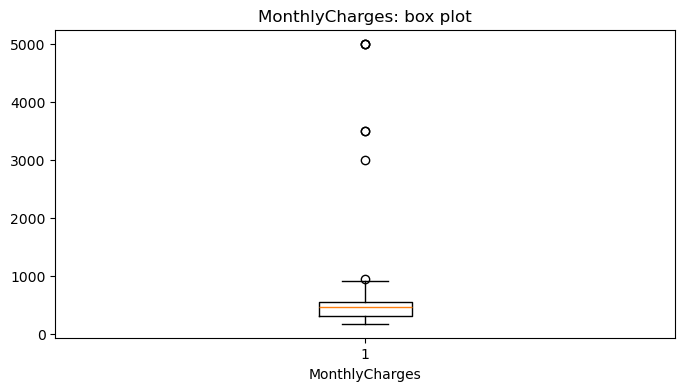

In [160]:
Q1 = data["MonthlyCharges"].quantile(0.25)
Q3 = data["MonthlyCharges"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
print(f"Q1={Q1:.1f}  Q3={Q3:.1f}  IQR={IQR:.1f}  ->  valid range: {lower:.1f} to {upper:.1f}")

outlier_mask = (data["MonthlyCharges"] < lower) | (data["MonthlyCharges"] > upper)
print("Number of outliers:", outlier_mask.sum())

plt.boxplot(data["MonthlyCharges"])
plt.title("MonthlyCharges: box plot")
plt.xlabel("MonthlyCharges")
plt.show()

### ✏️ Question B7
Remove the outliers, recalculate `TotalCharges = MonthlyCharges × TenureMonths`, and print the final shape.

In [161]:
data = data[~outlier_mask].copy()
data["TotalCharges"] = data["MonthlyCharges"] * data["TenureMonths"]
data = data.reset_index(drop=True)
print("Final shape:", data.shape)

Final shape: (993, 16)


💡 **Business insight:** Summarise what you cleaned and why it matters before analysis.

> **Answer:** I removed duplicate customers (they would be counted twice), standardised City and Name (so `'KOCHI'` and `'kochi'` are one city, not two), converted SignupDate to a real date, filled missing values with the median (numbers) or mode (categories) instead of deleting rows, recomputed SeniorCitizen from Age so it stays consistent, and removed MonthlyCharges outliers using the IQR rule, then recalculated TotalCharges. Clean data matters because wrong counts, split categories and extreme values would give misleading churn rates and a weaker model.

---
## Part C: EDA, Answering the Manager's Questions 🔍
For each question: calculate the **churn rate per group** (`groupby(...)['Churn'].mean()`) and draw a chart.

### ✏️ Question C1
**Which contract type churns the most?** Show the churn rate by `Contract` as a bar chart.

Contract
Month-to-month    51.2
One year          18.4
Two year          13.7
Name: Churn, dtype: float64


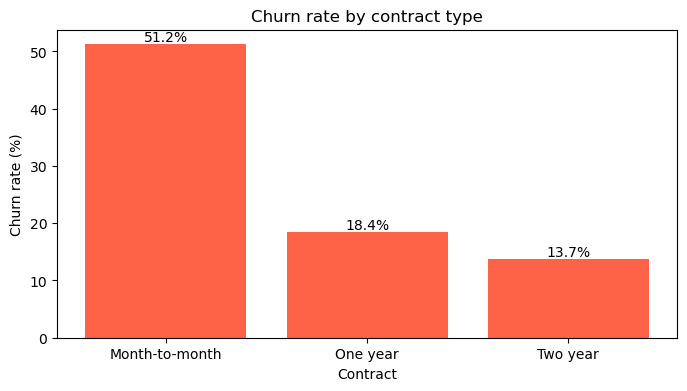

In [162]:
contract_churn = data.groupby("Contract")["Churn"].mean().sort_values(ascending=False)
print((contract_churn * 100).round(1))

bars = plt.bar(contract_churn.index, contract_churn.values * 100, color="tomato")
plt.bar_label(bars, fmt="%.1f%%")
plt.title("Churn rate by contract type")
plt.xlabel("Contract")
plt.ylabel("Churn rate (%)")
plt.show()

### ✏️ Question C2
**Do plan and payment method matter?** Make side-by-side bar charts of the churn rate by `Plan` and by `PaymentMethod`.

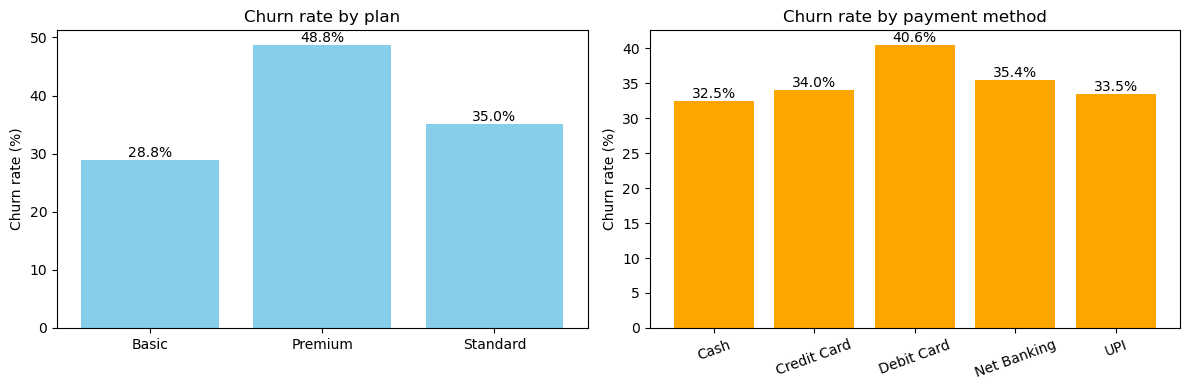

In [163]:
plan_churn = data.groupby("Plan")["Churn"].mean() * 100
pay_churn = data.groupby("PaymentMethod")["Churn"].mean() * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

b1 = ax1.bar(plan_churn.index, plan_churn.values, color="skyblue")
ax1.bar_label(b1, fmt="%.1f%%")
ax1.set_title("Churn rate by plan")
ax1.set_ylabel("Churn rate (%)")

b2 = ax2.bar(pay_churn.index, pay_churn.values, color="orange")
ax2.bar_label(b2, fmt="%.1f%%")
ax2.set_title("Churn rate by payment method")
ax2.set_ylabel("Churn rate (%)")
ax2.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

### ✏️ Question C3
**Do unhappy customers call support more?** Compare the average `SupportCalls`, `SatisfactionScore`, `TenureMonths` and `MonthlyCharges` for churned vs stayed customers.

In [164]:
compare = data.groupby("Churn")[["SupportCalls", "SatisfactionScore", "TenureMonths", "MonthlyCharges"]].mean().round(2)
compare.index = compare.index.map({0: "Stayed", 1: "Churned"})
compare

,SupportCalls,SatisfactionScore,TenureMonths,MonthlyCharges
Churn,,,,
Stayed,1.28,3.37,41.15,446.17
Churned,1.85,2.59,27.80,510.64


### ✏️ Question C4
Plot the **churn rate for each number of support calls**. What pattern do you see?

SupportCalls
0     19.9
1     30.6
2     44.3
3     47.0
4     50.0
5     60.0
6    100.0
Name: Churn, dtype: float64


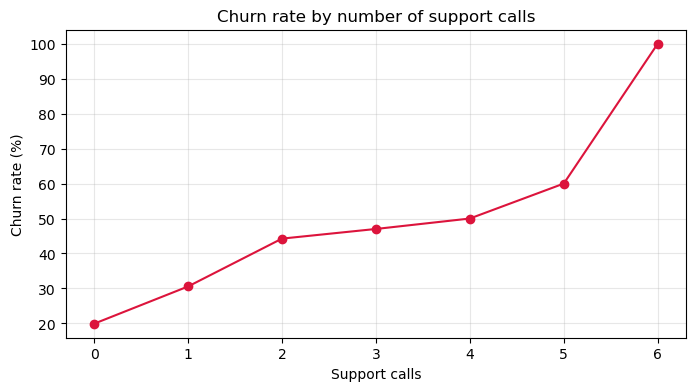

In [165]:
calls_churn = data.groupby("SupportCalls")["Churn"].mean() * 100
print(calls_churn.round(1))

plt.plot(calls_churn.index, calls_churn.values, marker="o", color="crimson")
plt.title("Churn rate by number of support calls")
plt.xlabel("Support calls")
plt.ylabel("Churn rate (%)")
plt.grid(alpha=0.3)
plt.show()

### ✏️ Question C5
**Does loyalty (tenure) matter?** Plot overlapping histograms of `TenureMonths` for churned and stayed customers.

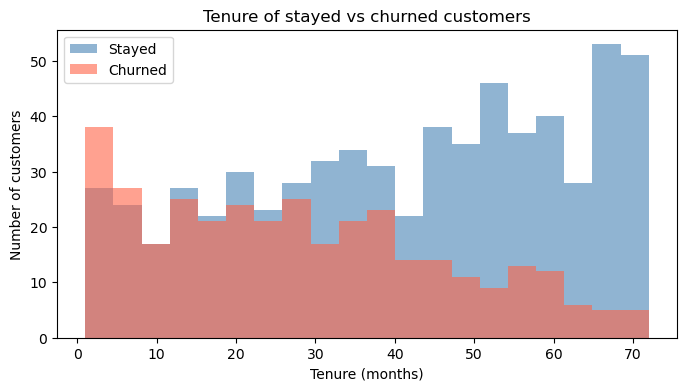

In [166]:
plt.hist(data.loc[data["Churn"] == 0, "TenureMonths"], bins=20, alpha=0.6, label="Stayed", color="steelblue")
plt.hist(data.loc[data["Churn"] == 1, "TenureMonths"], bins=20, alpha=0.6, label="Churned", color="tomato")
plt.title("Tenure of stayed vs churned customers")
plt.xlabel("Tenure (months)")
plt.ylabel("Number of customers")
plt.legend()
plt.show()

### ✏️ Question C6
**Satisfaction vs churn:** show the churn rate for each `SatisfactionScore` (1–5).

SatisfactionScore
1.0    51.3
2.0    50.0
3.0    36.7
4.0    25.7
5.0    15.2
Name: Churn, dtype: float64


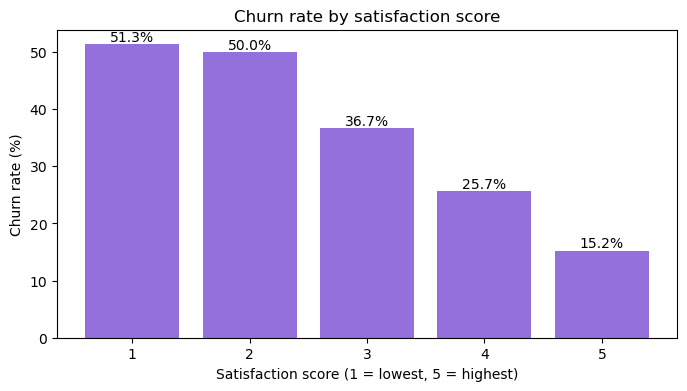

In [167]:
sat_churn = data.groupby("SatisfactionScore")["Churn"].mean() * 100
print(sat_churn.round(1))

bars = plt.bar(sat_churn.index.astype(int).astype(str), sat_churn.values, color="mediumpurple")
plt.bar_label(bars, fmt="%.1f%%")
plt.title("Churn rate by satisfaction score")
plt.xlabel("Satisfaction score (1 = lowest, 5 = highest)")
plt.ylabel("Churn rate (%)")
plt.show()

### ✏️ Question C7
**Which city loses the most customers?** Show the number of customers, the number who churned, and the churn rate per city, sorted by churn rate.

In [168]:
city_stats = data.groupby("City").agg(
    customers=("Churn", "count"),
    churned=("Churn", "sum"),
    churn_rate=("Churn", "mean"),
)
city_stats["churn_rate"] = (city_stats["churn_rate"] * 100).round(1)
city_stats.sort_values("churn_rate", ascending=False)

,customers,churned,churn_rate
City,,,
Bengaluru,145,61,42.1
Chennai,92,34,37.0
Kollam,99,36,36.4
Kochi,274,99,36.1
Kozhikode,128,45,35.2
Thrissur,112,33,29.5
Thiruvananthapuram,143,40,28.0


### ✏️ Question C8
Make a **correlation heatmap** of the numeric columns. Which feature is most strongly linked with `Churn`?

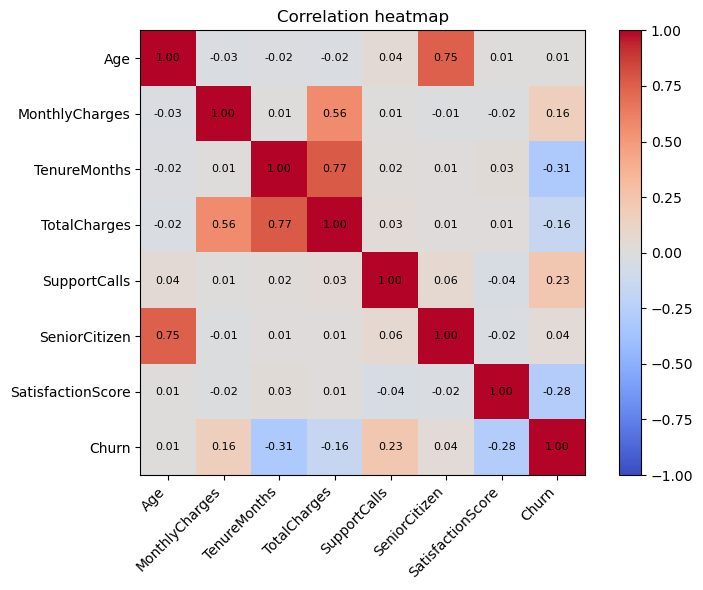

TenureMonths        -0.306
SatisfactionScore   -0.279
SupportCalls         0.225
MonthlyCharges       0.159
TotalCharges        -0.155
SeniorCitizen        0.037
Age                  0.006
Name: Churn, dtype: float64


In [169]:
corr = data.select_dtypes(include="number").corr()

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im)
ax.set_title("Correlation heatmap")
plt.tight_layout()
plt.show()
churn_corr = corr["Churn"].drop("Churn")
print(churn_corr.reindex(churn_corr.abs().sort_values(ascending=False).index).round(3))

💡 **Business insight:** Write the top 3 reasons customers churn, based on your EDA.

> **Answer (check each point against your own charts and numbers):**
> 1. **Contract type:** month-to-month customers churn far more than 1-year/2-year customers (C1), as they can leave at any time.
> 2. **Poor experience:** churned customers make more support calls and give lower satisfaction scores (C3, C4, C6).
> 3. **Short tenure:** most churn happens early in the customer's life, while long-tenure customers are loyal (C5).

---
## Part C2: Visualising with Matplotlib 📊
Pandas' `.plot()` is a shortcut. **Matplotlib** gives you full control, and it's what you'll use for reports and presentations.

**Cheat sheet**
| Chart | Function | Use it for |
|---|---|---|
| Bar | `plt.bar(x, height)` / `plt.barh` | Comparing categories |
| Histogram | `plt.hist(values, bins=)` | Distribution of one number |
| Box plot | `plt.boxplot([group1, group2])` | Spread and outliers by group |
| Scatter | `plt.scatter(x, y, c=)` | Relationship between two numbers |
| Line | `plt.plot(x, y, marker="o")` | Trends / ordered values |
| Pie | `plt.pie(sizes, labels=, autopct=)` | Parts of a whole |

**Every chart:** `plt.figure(figsize=)` → plot → `plt.title` / `plt.xlabel` / `plt.ylabel` → `plt.legend()` / `plt.grid()` → `plt.show()` (or `plt.savefig("file.png")`).

### ✏️ Question V1
**Figure anatomy:** use `plt.bar` to draw the number of customers who **stayed vs churned**. Add a title, axis labels, a grid on the y-axis, and give the bars different colours.

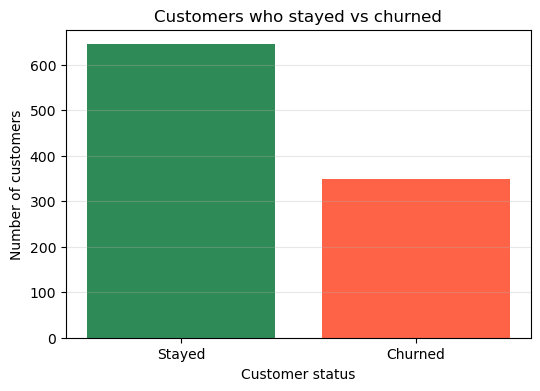

In [170]:
counts = data["Churn"].value_counts().sort_index()     
plt.figure(figsize=(6, 4))
plt.bar(["Stayed", "Churned"], counts.values, color=["seagreen", "tomato"])
plt.title("Customers who stayed vs churned")
plt.xlabel("Customer status")
plt.ylabel("Number of customers")
plt.grid(axis="y", alpha=0.3)
plt.show()

### ✏️ Question V2
**Bar chart with value labels:** plot the churn rate (%) by `Contract` and write each percentage on top of its bar.

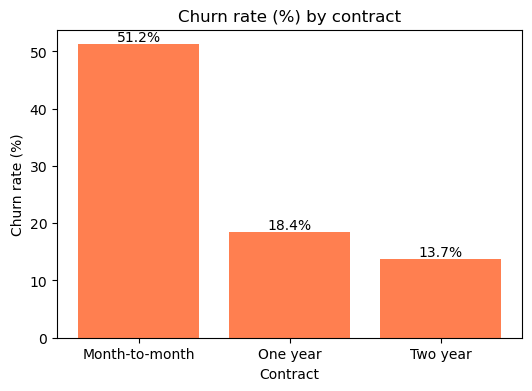

In [171]:
rate = data.groupby("Contract")["Churn"].mean() * 100
plt.figure(figsize=(6, 4))
bars = plt.bar(rate.index, rate.values, color="coral")
plt.bar_label(bars, fmt="%.1f%%")
plt.title("Churn rate (%) by contract")
plt.xlabel("Contract")
plt.ylabel("Churn rate (%)")
plt.show()

### ✏️ Question V3
**Grouped bar chart:** for each `Plan`, show the number of customers who stayed and who churned as two bars side by side.

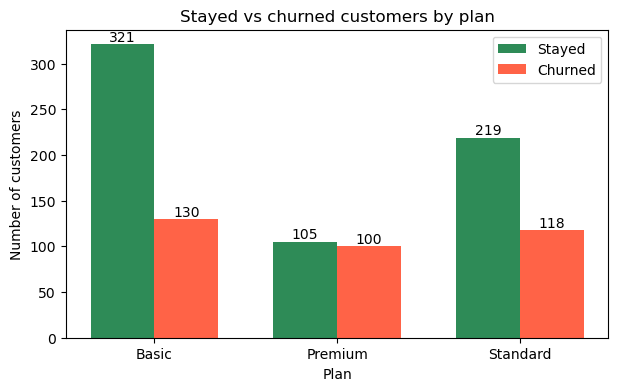

In [172]:
ct = pd.crosstab(data["Plan"], data["Churn"])         
x = np.arange(len(ct))
width = 0.35

plt.figure(figsize=(7, 4))
b1 = plt.bar(x - width / 2, ct[0], width, label="Stayed", color="seagreen")
b2 = plt.bar(x + width / 2, ct[1], width, label="Churned", color="tomato")
plt.bar_label(b1)
plt.bar_label(b2)
plt.xticks(x, ct.index)
plt.title("Stayed vs churned customers by plan")
plt.xlabel("Plan")
plt.ylabel("Number of customers")
plt.legend()
plt.show()

### ✏️ Question V4
**Histogram:** draw overlapping histograms of `TenureMonths` for stayed and churned customers (use `alpha` and a legend).

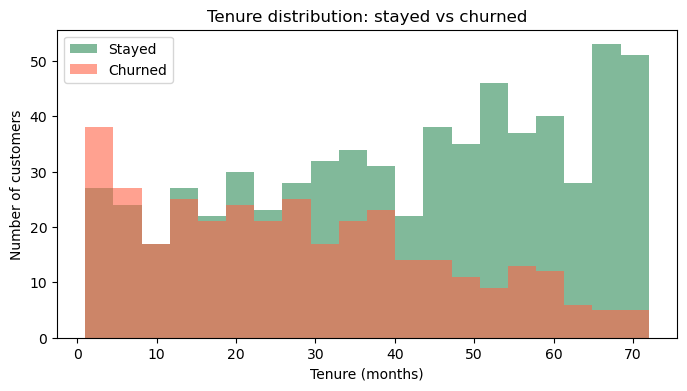

In [173]:
plt.figure(figsize=(8, 4))
plt.hist(data.loc[data["Churn"] == 0, "TenureMonths"], bins=20, alpha=0.6, color="seagreen", label="Stayed")
plt.hist(data.loc[data["Churn"] == 1, "TenureMonths"], bins=20, alpha=0.6, color="tomato", label="Churned")
plt.title("Tenure distribution: stayed vs churned")
plt.xlabel("Tenure (months)")
plt.ylabel("Number of customers")
plt.legend()
plt.show()

### ✏️ Question V5
**Box plot:** compare `MonthlyCharges` across the three plans with `plt.boxplot`.

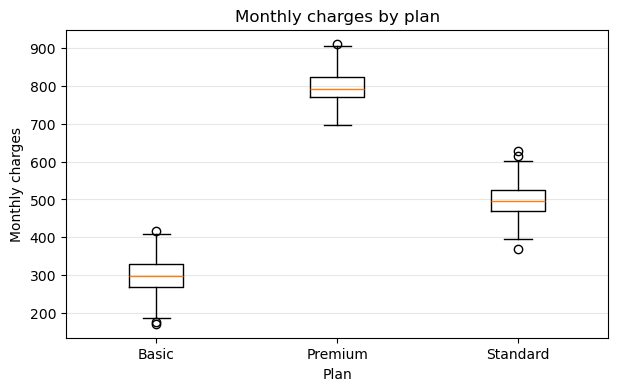

In [174]:
plans = sorted(data["Plan"].unique())
groups = [data.loc[data["Plan"] == p, "MonthlyCharges"] for p in plans]

plt.figure(figsize=(7, 4))
plt.boxplot(groups)
plt.xticks(range(1, len(plans) + 1), plans)
plt.title("Monthly charges by plan")
plt.xlabel("Plan")
plt.ylabel("Monthly charges")
plt.grid(axis="y", alpha=0.3)
plt.show()

### ✏️ Question V6
**Scatter plot:** plot `TenureMonths` (x) vs `MonthlyCharges` (y), red for churned and blue for stayed. Where do the churners cluster?

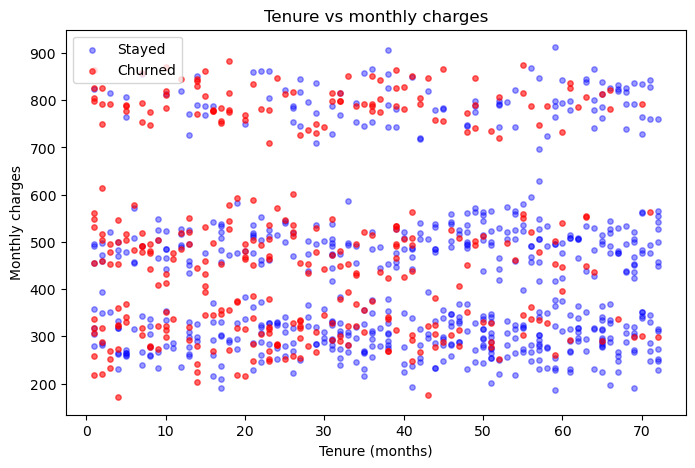

In [175]:
stayed = data[data["Churn"] == 0]
churned = data[data["Churn"] == 1]

plt.figure(figsize=(8, 5))
plt.scatter(stayed["TenureMonths"], stayed["MonthlyCharges"], c="blue", alpha=0.4, s=15, label="Stayed")
plt.scatter(churned["TenureMonths"], churned["MonthlyCharges"], c="red", alpha=0.6, s=15, label="Churned")
plt.title("Tenure vs monthly charges")
plt.xlabel("Tenure (months)")
plt.ylabel("Monthly charges")
plt.legend()
plt.show()

### ✏️ Question V7
**Pie + line in one figure:** using `plt.subplots(1, 2)`, draw (left) a pie of the churn split with percentages and (right) a line chart of churn rate by `SatisfactionScore`.

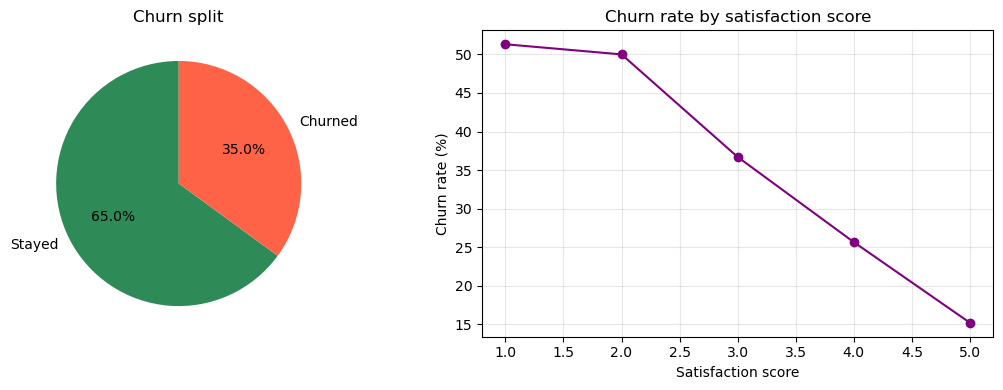

In [176]:
split = data["Churn"].value_counts().sort_index()
sat_rate = data.groupby("SatisfactionScore")["Churn"].mean() * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.pie(split.values, labels=["Stayed", "Churned"], autopct="%1.1f%%",
        colors=["seagreen", "tomato"], startangle=90)
ax1.set_title("Churn split")

ax2.plot(sat_rate.index, sat_rate.values, marker="o", color="purple")
ax2.set_title("Churn rate by satisfaction score")
ax2.set_xlabel("Satisfaction score")
ax2.set_ylabel("Churn rate (%)")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### ✏️ Question V8
📊 **Manager dashboard:** build a 2×2 figure with `plt.subplots(2, 2)` showing (1) churn rate by contract, (2) churn rate by support calls, (3) tenure histograms for churned vs stayed, (4) churn rate by payment method. Give it an overall title with `fig.suptitle` and save it as `churn_dashboard.png`.

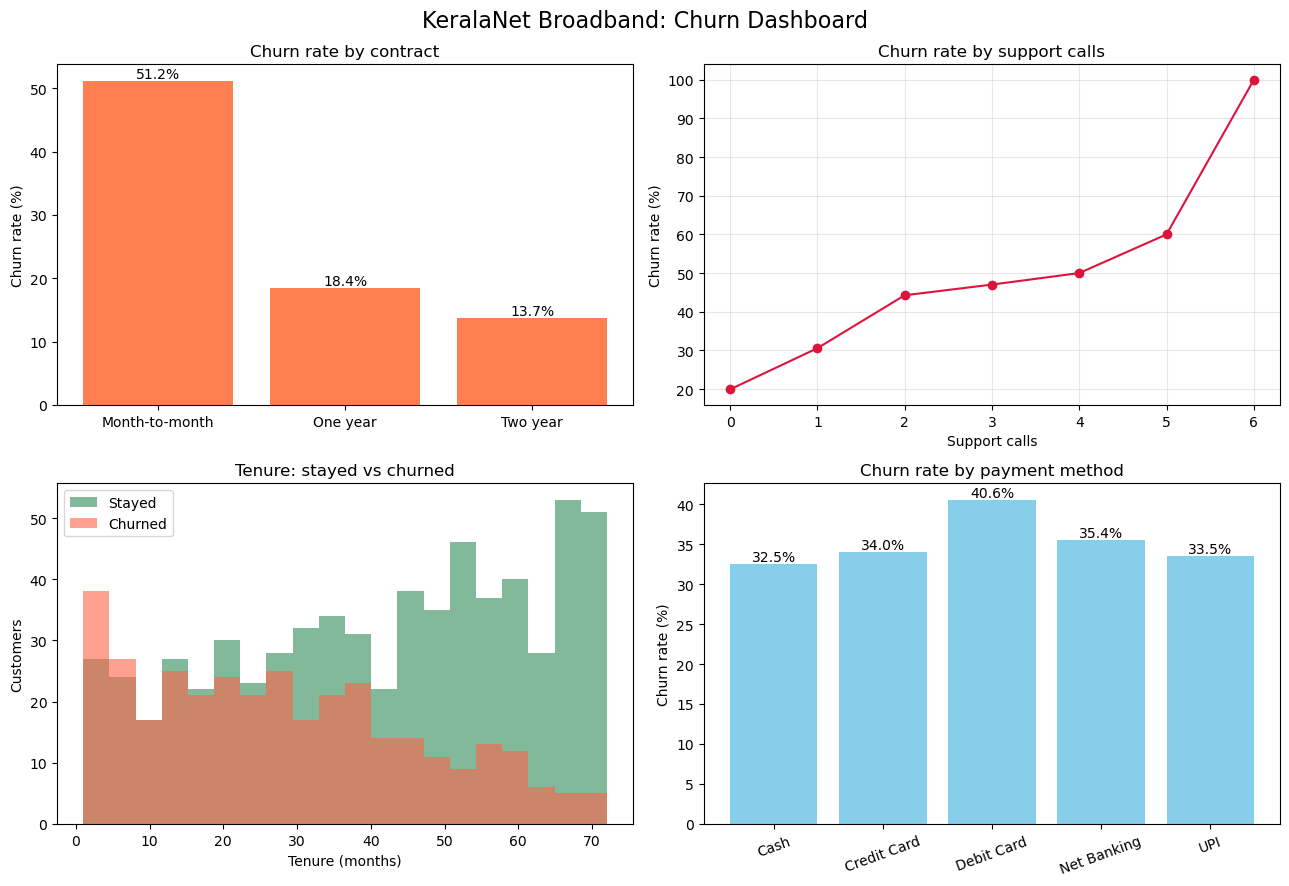

In [177]:
contract_rate = data.groupby("Contract")["Churn"].mean() * 100
calls_rate = data.groupby("SupportCalls")["Churn"].mean() * 100
pay_rate = data.groupby("PaymentMethod")["Churn"].mean() * 100

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# (1) churn rate by contract
b = axes[0, 0].bar(contract_rate.index, contract_rate.values, color="coral")
axes[0, 0].bar_label(b, fmt="%.1f%%")
axes[0, 0].set_title("Churn rate by contract")
axes[0, 0].set_ylabel("Churn rate (%)")

# (2) churn rate by support calls
axes[0, 1].plot(calls_rate.index, calls_rate.values, marker="o", color="crimson")
axes[0, 1].set_title("Churn rate by support calls")
axes[0, 1].set_xlabel("Support calls")
axes[0, 1].set_ylabel("Churn rate (%)")
axes[0, 1].grid(alpha=0.3)

# (3) tenure histograms
axes[1, 0].hist(data.loc[data["Churn"] == 0, "TenureMonths"], bins=20, alpha=0.6, color="seagreen", label="Stayed")
axes[1, 0].hist(data.loc[data["Churn"] == 1, "TenureMonths"], bins=20, alpha=0.6, color="tomato", label="Churned")
axes[1, 0].set_title("Tenure: stayed vs churned")
axes[1, 0].set_xlabel("Tenure (months)")
axes[1, 0].set_ylabel("Customers")
axes[1, 0].legend()

# (4) churn rate by payment method
b = axes[1, 1].bar(pay_rate.index, pay_rate.values, color="skyblue")
axes[1, 1].bar_label(b, fmt="%.1f%%")
axes[1, 1].set_title("Churn rate by payment method")
axes[1, 1].set_ylabel("Churn rate (%)")
axes[1, 1].tick_params(axis="x", rotation=20)

fig.suptitle("KeralaNet Broadband: Churn Dashboard", fontsize=16)
plt.tight_layout()
fig.savefig("churn_dashboard.png", dpi=150)
plt.show()

💡 **Business insight:** Which chart would you put on the first slide for your manager, and why?

> **Answer:** The **churn rate by contract** bar chart (V2), because it is simple, shows the biggest gap between groups with clear % labels, and points directly to an action (move customers off month-to-month plans). The 2×2 dashboard is better for the second slide as supporting evidence.

---
## Part D: Prepare the Data for a Model 🛠️
A model needs **numbers only**, a clear **target**, and separate **train** and **test** data.

### ✏️ Question D1
Create `X` from the features `TenureMonths`, `MonthlyCharges`, `SupportCalls`, `SatisfactionScore`, `Age`, `Contract`, `Plan`, `PaymentMethod`, and set `y = data['Churn']`.

In [178]:
features = ["TenureMonths", "MonthlyCharges", "SupportCalls", "SatisfactionScore",
            "Age", "Contract", "Plan", "PaymentMethod"]
X = data[features]
y = data["Churn"]
print(X.shape, y.shape)
X.head()

(993, 8) (993,)


,TenureMonths,MonthlyCharges,SupportCalls,SatisfactionScore,Age,Contract,Plan,PaymentMethod
0,13,521.61,0,2.0,66.0,One year,Standard,Debit Card
1,2,503.05,2,1.0,18.0,One year,Standard,Net Banking
2,44,538.37,3,4.0,74.0,One year,Standard,UPI
3,12,494.45,2,3.0,66.0,Month-to-month,Standard,Credit Card
4,17,520.10,0,1.0,38.0,Month-to-month,Standard,UPI


### ✏️ Question D2
Models can't read text. **One-hot encode** `Contract`, `Plan` and `PaymentMethod` with `pd.get_dummies(..., drop_first=True, dtype=int)`.

In [179]:
X = pd.get_dummies(X, columns=["Contract", "Plan", "PaymentMethod"], drop_first=True, dtype=int)
print(X.shape)
X.head()

(993, 13)


,TenureMonths,MonthlyCharges,SupportCalls,SatisfactionScore,Age,Contract_One year,Contract_Two year,Plan_Premium,Plan_Standard,PaymentMethod_Credit Card,PaymentMethod_Debit Card,PaymentMethod_Net Banking,PaymentMethod_UPI
0,13,521.61,0,2.0,66.0,1,0,0,1,0,1,0,0
1,2,503.05,2,1.0,18.0,1,0,0,1,0,0,1,0
2,44,538.37,3,4.0,74.0,1,0,0,1,0,0,0,1
3,12,494.45,2,3.0,66.0,0,0,0,1,1,0,0,0
4,17,520.10,0,1.0,38.0,0,0,0,1,0,0,0,1


### ✏️ Question D3
Split the data 80/20 into train and test sets with `train_test_split` (`random_state=42`, `stratify=y`).

In [180]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (794, 13) | Test: (199, 13)


### ✏️ Question D4
**Scale** the features with `StandardScaler`: `fit_transform` on the training set, `transform` on the test set.

In [181]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  
X_test_scaled = scaler.transform(X_test)         
print(X_train_scaled.shape, X_test_scaled.shape)

(794, 13) (199, 13)


### ✏️ Question D5
Check that the churn ratio is similar in `y_train` and `y_test`.

In [182]:
print("Churn ratio in y_train:", round(y_train.mean(), 4))
print("Churn ratio in y_test :", round(y_test.mean(), 4))

Churn ratio in y_train: 0.3501
Churn ratio in y_test : 0.3518


---
## Part E: Logistic Regression 🤖
Logistic regression outputs a **probability of churn** between 0 and 1. If it's ≥ 0.5, we predict **churn**.

### ✏️ Question E1
Create a `LogisticRegression()` model and fit it on the scaled training data.

In [183]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)
print("Model trained ✅")

Model trained ✅


### ✏️ Question E2
Predict on the test set. Show a table of the first 10 rows with **Actual**, **Predicted** and **P(churn)**.

In [184]:
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]     # column 1 = probability of churn (class 1)

results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "P(churn)": y_prob.round(3),
})
results.head(10)

,Actual,Predicted,P(churn)
0,0,0,0.074
1,0,0,0.019
2,1,1,0.922
3,0,0,0.113
4,0,1,0.614
5,0,0,0.402
6,0,0,0.072
7,0,1,0.647
8,0,0,0.026
9,1,1,0.727


### ✏️ Question E3
Print the **accuracy** and the **classification report**, and plot the **confusion matrix**.

Accuracy: 0.7789

              precision    recall  f1-score   support

      Stayed       0.81      0.86      0.83       129
     Churned       0.71      0.63      0.67        70

    accuracy                           0.78       199
   macro avg       0.76      0.74      0.75       199
weighted avg       0.77      0.78      0.78       199



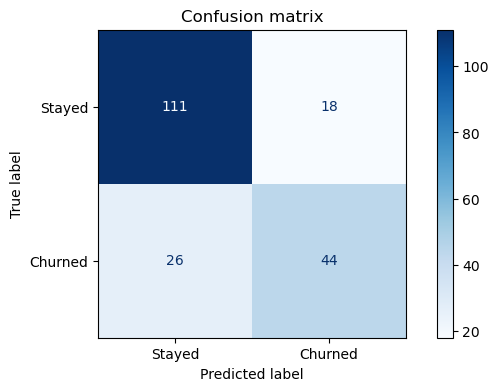

In [185]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred, target_names=["Stayed", "Churned"]))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Stayed", "Churned"]).plot(cmap="Blues")
plt.title("Confusion matrix")
plt.show()

### ✏️ Question E3b
**Confusion matrix in plain matplotlib:** draw it yourself with `plt.imshow` and write each count in its cell.

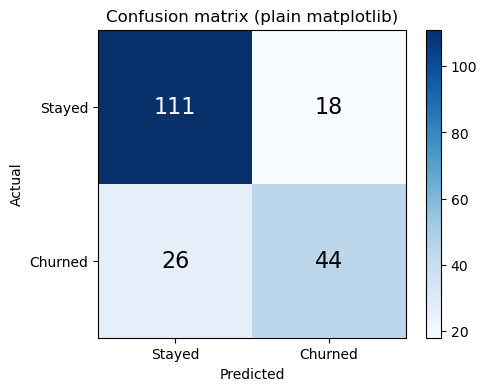

In [186]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks([0, 1], ["Stayed", "Churned"])
plt.yticks([0, 1], ["Stayed", "Churned"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=16,
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.title("Confusion matrix (plain matplotlib)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### ✏️ Question E4
Show the model's **coefficients** as a sorted horizontal bar chart. Which features push churn up, and which pull it down?

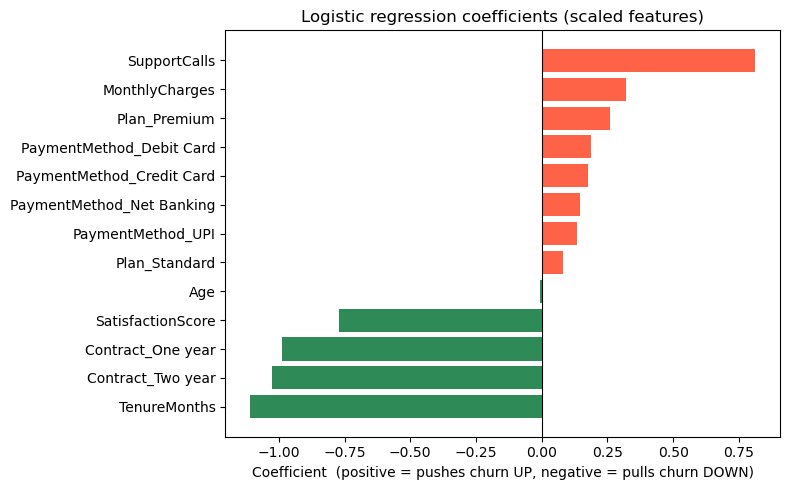

Push churn UP  : ['SupportCalls', 'MonthlyCharges', 'Plan_Premium', 'PaymentMethod_Debit Card', 'PaymentMethod_Credit Card', 'PaymentMethod_Net Banking', 'PaymentMethod_UPI', 'Plan_Standard']
Pull churn DOWN: ['TenureMonths', 'Contract_Two year', 'Contract_One year', 'SatisfactionScore', 'Age']


In [187]:
coefs = pd.Series(model.coef_[0], index=X.columns).sort_values()

plt.figure(figsize=(8, 5))
plt.barh(coefs.index, coefs.values, color=["tomato" if c > 0 else "seagreen" for c in coefs.values])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic regression coefficients (scaled features)")
plt.xlabel("Coefficient  (positive = pushes churn UP, negative = pulls churn DOWN)")
plt.tight_layout()
plt.show()

print("Push churn UP  :", coefs[coefs > 0].sort_values(ascending=False).index.tolist())
print("Pull churn DOWN:", coefs[coefs < 0].index.tolist())

### ✏️ Question E5
🎯 **Predict for a new customer:** 3 months tenure, ₹550 per month, 4 support calls, satisfaction 2, age 30, month-to-month contract, Standard plan, pays by UPI. What is their churn probability?

In [196]:
new_customer = pd.Series(0.0, index=X.columns)
new_customer["TenureMonths"] = 3
new_customer["MonthlyCharges"] = 550
new_customer["SupportCalls"] = 4
new_customer["SatisfactionScore"] = 2
new_customer["Age"] = 30

for prefix, keyword in [("Contract", "month"), ("Plan", "standard"), ("PaymentMethod", "upi")]:
    matches = [c for c in X.columns if c.startswith(prefix + "_") and keyword in c.lower()]
    new_customer[matches] = 1
    print(prefix, "->", matches if matches else "baseline category (all dummies 0)")

new_df = pd.DataFrame([new_customer.values], columns=X.columns)
new_scaled = scaler.transform(new_df)                 # same scaler as the training data
prob = model.predict_proba(new_scaled)[0, 1]
print(f"\nChurn probability: {prob:.1%}")
print("Prediction:", "WILL CHURN ⚠️" if prob >= 0.5 else "Will stay ✅")

Contract -> baseline category (all dummies 0)
Plan -> ['Plan_Standard']
PaymentMethod -> ['PaymentMethod_UPI']

Churn probability: 98.5%
Prediction: WILL CHURN ⚠️


💡 **Business insight:** Is this model useful to the manager? What does it get right, and what does it miss?

> **Answer:** Yes, it is useful as an early-warning tool: it gives each customer a churn probability, so the team can call the highest-risk customers first, and its coefficients confirm the EDA (short tenure, low satisfaction and many support calls raise risk; long contracts lower it). Its limits: with the default 0.5 threshold it misses some real churners (see recall for churn in your report), it is linear so it cannot capture complex interactions, and it only uses 8 features (no usage or billing-dispute data). Lowering the threshold (F2) catches more churners at the cost of more false alarms.

---
## Part F: Recommendations & Challenges 🚀

### ✏️ Question F1
Write **3 recommendations** for the manager as a markdown cell or `print` statements, based on your analysis.

In [189]:
print("1. Push customers from month-to-month onto 1-year or 2-year contracts with a discount or free upgrade; month-to-month is where churn is highest.")
print("2. Treat 3+ support calls as an early-warning flag: have a senior agent call back within 24 hours and fix the issue before the customer leaves.")
print("3. Focus on the first months: onboarding calls, a welcome offer and a satisfaction check at months 1 and 3, because new customers (short tenure) with low satisfaction churn the most.")

1. Push customers from month-to-month onto 1-year or 2-year contracts with a discount or free upgrade; month-to-month is where churn is highest.
2. Treat 3+ support calls as an early-warning flag: have a senior agent call back within 24 hours and fix the issue before the customer leaves.
3. Focus on the first months: onboarding calls, a welcome offer and a satisfaction check at months 1 and 3, because new customers (short tenure) with low satisfaction churn the most.


### ⭐ Challenge questions (optional)

### ✏️ Question F2
**Threshold tuning:** predict churn when P(churn) ≥ **0.35** instead of 0.5. How do recall and precision for churners change?

In [195]:
from sklearn.metrics import precision_score, recall_score

pred_05 = (y_prob >= 0.50).astype(int)
pred_035 = (y_prob >= 0.35).astype(int)

compare_th = pd.DataFrame({
    "Threshold": [0.50, 0.35],
    "Precision (churn)": [precision_score(y_test, pred_05), precision_score(y_test, pred_035)],
    "Recall (churn)": [recall_score(y_test, pred_05), recall_score(y_test, pred_035)],
    "Accuracy": [accuracy_score(y_test, pred_05), accuracy_score(y_test, pred_035)],
}).round(3)
print(compare_th)


   Threshold  Precision (churn)  Recall (churn)  Accuracy
0       0.50               0.71           0.629     0.779
1       0.35               0.63           0.729     0.754


### ✏️ Question F3
**Remove a feature:** retrain without the `Contract` columns. How much does accuracy drop? What does that tell you?

In [194]:
X_nc = X.drop(columns=[c for c in X.columns if c.startswith("Contract_")])

Xtr, Xte, ytr, yte = train_test_split(X_nc, y, test_size=0.2, random_state=42, stratify=y)
sc2 = StandardScaler()
Xtr_s = sc2.fit_transform(Xtr)
Xte_s = sc2.transform(Xte)

model_nc = LogisticRegression(max_iter=1000).fit(Xtr_s, ytr)
acc_full = accuracy_score(y_test, y_pred)
acc_nc = accuracy_score(yte, model_nc.predict(Xte_s))
print(f"Accuracy with Contract   : {acc_full:.4f}")
print(f"Accuracy without Contract: {acc_nc:.4f}")
print(f"Drop                     : {(acc_full - acc_nc) * 100:.2f} percentage points")


Accuracy with Contract   : 0.7789
Accuracy without Contract: 0.7085
Drop                     : 7.04 percentage points


### ✏️ Question F4
**Try another model:** fit a `DecisionTreeClassifier(max_depth=4, random_state=42)` and compare its accuracy.

In [193]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(max_depth=4, random_state=42)
tree.fit(X_train, y_train)             
tree_acc = accuracy_score(y_test, tree.predict(X_test))

print(f"Logistic Regression accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Decision Tree accuracy      : {tree_acc:.4f}")

Logistic Regression accuracy: 0.7789
Decision Tree accuracy      : 0.7337


---
## 🎉 Well done!
You just completed a real data-analysis workflow: **load → clean → explore → prepare → model → recommend**. This is what data analysts and data scientists do every day.

**Next ideas:** try this workflow on a dataset you care about (cricket stats, Kerala rainfall, movie ratings from Kaggle), or learn more models (random forests, XGBoost).